# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Tangaran, Grisby Paul James
- _Student No._: 2024-02777
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [3]:
def y1(x):
    return np.sqrt(9 - 4*x**2)
    
def y2(x):
    return (-x**2 + 1)

def y3(x):
    return (np.sqrt(x)*np.cos(x))

In [11]:
def trapezoid(f, a, b, n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5
    fs = f(xs)
    contribs = cs*fs
    return h*np.sum(contribs), h*np.sum(cs*np.abs(fs))

def simpson13(f, a, b, n):         
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    fs = f(xs)
    return (h/3)*np.sum(cs*fs), (h/3)*np.sum(cs*np.abs(fs))

def simpson38(f, a, b, n):          
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 3*np.ones(n)
    cs[3:-1:3] = 2; cs[0] = 1; cs[-1] = 1
    fs = f(xs)
    return (3*h/8)*np.sum(cs*fs), (3*h/8)*np.sum(cs*np.abs(fs))


def montecarlo(f, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)

    if option == "uniform":
        fs = f(us)
    else:
        c0 = 4 - 2*np.sqrt(2)
        c1 = -6 + 4*np.sqrt(2)
        xs = (-c0 + np.sqrt(2*c1*us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs)

    fbar, err = stats(fs)
    absbar, abserr = stats(np.abs(fs))      
    return (b - a)*fbar, (b - a)*absbar, (b - a)*err

def stats(fs):
    n = fs.size
    fbar = np.sum(fs)/n
    fsq = np.sum(fs**2)/n
    varfbar = (fsq - fbar**2)/(n - 1)
    return fbar, np.sqrt(varfbar)

In [12]:
tests = [(y1, 0, 1.5, "y = sqrt(9 - 4x^2)"), (y2, -2, 2, "y = -x^2 + 1"), (y3, 0, np.pi, "y = sqrt(x) * cos(x)")]

n = 601          # number of points (600 intervals) for the Newton-Cotes rules
n_mc = 100000    # number of random points for Monte Carlo

for f, a, b, name in tests:

    def abs_f(x):                      
        return np.abs(f(x))

    exact, quad_err = quad(f, a, b)
    exact_area, quad_err = quad(abs_f, a, b)

    trap, trap_area = trapezoid(f, a, b, n)
    s13, s13_area = simpson13(f, a, b, n)
    s38, s38_area = simpson38(f, a, b, n)
    mc, mc_area, _ = montecarlo(f, a, b, n_mc)

    print(name)
    print(f"  scipy quad : integral = {exact:.6f}, area = {exact_area:.6f}")
    print(f"  Trapezoid  : integral = {trap:.6f}, area = {trap_area:.6f}")
    print(f"  Simpson 1/3: integral = {s13:.6f}, area = {s13_area:.6f}")
    print(f"  Simpson 3/8: integral = {s38:.6f}, area = {s38_area:.6f}")
    print(f"  Monte Carlo: integral = {mc:.6f}, area = {mc_area:.6f}")
    print()

y = sqrt(9 - 4x^2)
  scipy quad : integral = 3.534292, area = 3.534292
  Trapezoid  : integral = 3.534202, area = 3.534202
  Simpson 1/3: integral = 3.534257, area = 3.534257
  Simpson 3/8: integral = 3.534249, area = 3.534249
  Monte Carlo: integral = 3.533494, area = 3.533494

y = -x^2 + 1
  scipy quad : integral = -1.333333, area = 4.000000
  Trapezoid  : integral = -1.333363, area = 4.000000
  Simpson 1/3: integral = -1.333333, area = 4.000000
  Simpson 3/8: integral = -1.333333, area = 4.000000
  Monte Carlo: integral = -1.325427, area = 3.993214

y = sqrt(x) * cos(x)
  scipy quad : integral = -0.894831, area = 2.302907
  Trapezoid  : integral = -0.894911, area = 2.302823
  Simpson 1/3: integral = -0.894862, area = 2.302876
  Simpson 3/8: integral = -0.894869, area = 2.302870
  Monte Carlo: integral = -0.895133, area = 2.305399



Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

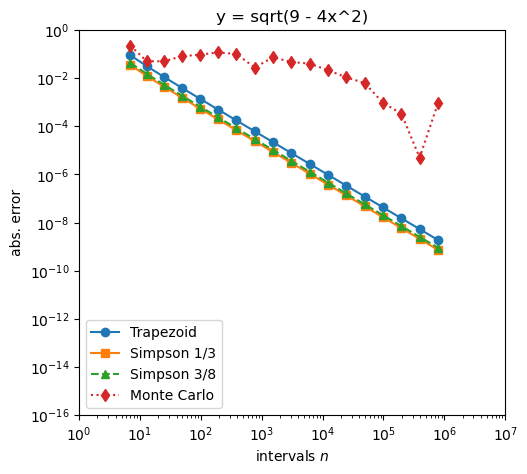

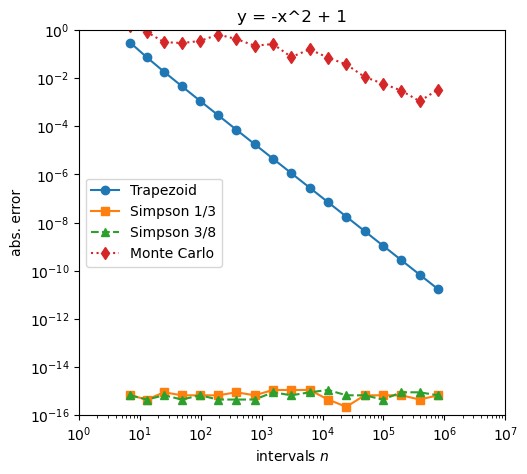

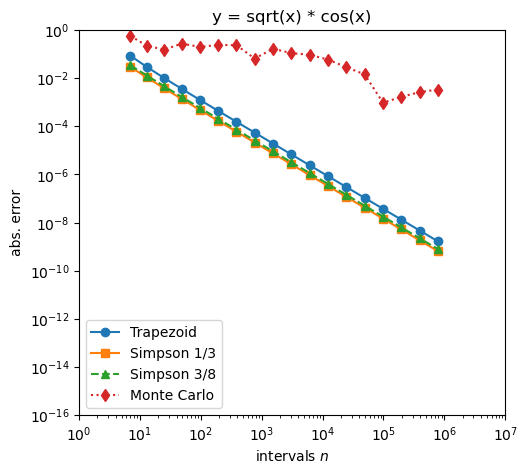

In [17]:
ns = [6*2**k + 1 for k in range(18)]   # 7, 13, 25, ..., 786433 points (n - 1 divisible by 2 and 3)

for f, a, b, name in tests:
    exact, quad_err = quad(f, a, b)

    err_trap = []
    err_s13 = []
    err_s38 = []
    err_mc = []
    for n in ns:
        err_trap.append(abs(trapezoid(f, a, b, n)[0] - exact))
        err_s13.append(abs(simpson13(f, a, b, n)[0] - exact))
        err_s38.append(abs(simpson38(f, a, b, n)[0] - exact))
        err_mc.append(abs(montecarlo(f, a, b, n)[0] - exact))

    plt.figure(figsize=(5.5, 5))
    plt.loglog(ns, err_trap, "o-", label="Trapezoid")
    plt.loglog(ns, err_s13, "s-", label="Simpson 1/3")
    plt.loglog(ns, err_s38, "^--", label="Simpson 3/8")
    plt.loglog(ns, err_mc, "d:", label="Monte Carlo")
    plt.xlim(1e0, 1e7)
    plt.ylim(1e-16, 1e0)
    plt.xlabel("intervals $n$")
    plt.ylabel("abs. error")
    plt.title(name)
    plt.legend()
    plt.show()

In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

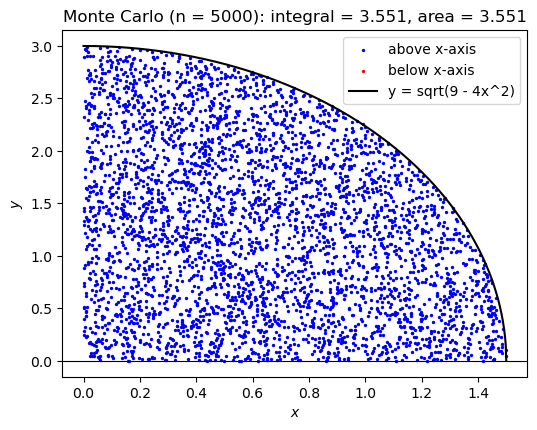

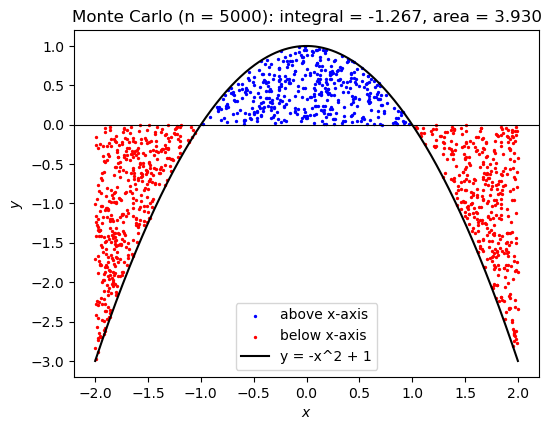

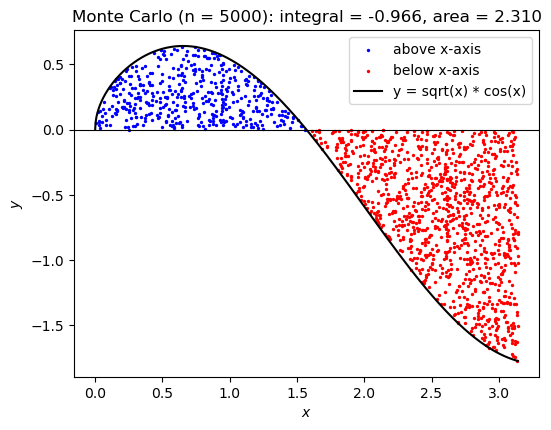

In [19]:
np.random.seed(0)
n_points = 5000    # number of random points for the plot

for f, a, b, name in tests:
    
    # box that contains the curve and the x-axis
    xcurve = np.linspace(a, b, 1000)
    ycurve = f(xcurve)
    ymin = min(0, ycurve.min())
    ymax = max(0, ycurve.max())
    box_area = (b - a)*(ymax - ymin)

    # random points inside the box
    xs = np.random.uniform(a, b, n_points)
    ys = np.random.uniform(ymin, ymax, n_points)
    fs = f(xs)

    # points between the curve and the x-axis
    above = (ys >= 0) & (ys <= fs)    # blue: above the x-axis
    below = (ys < 0) & (ys >= fs)     # red: below the x-axis

    #region area = box_area * (points in region)/(total points).
    integral = box_area*(np.sum(above) - np.sum(below))/n_points
    area = box_area*(np.sum(above) + np.sum(below))/n_points

    plt.figure(figsize=(6, 4.5))
    plt.scatter(xs[above], ys[above], s=2, color="blue", label="above x-axis")
    plt.scatter(xs[below], ys[below], s=2, color="red", label="below x-axis")
    plt.plot(xcurve, ycurve, color="black", label=name)
    plt.axhline(0, color="black", linewidth=1.0)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.title(f"Monte Carlo (n = {n_points}): integral = {integral:.3f}, area = {area:.3f}")
    plt.legend()
    plt.show()